In [123]:
import pandas as pd
df= pd.read_csv("dataset.csv")

df.head()

,id,full_text,favorites,retweets,mentions,country,user,followers,followees
0,183721,Flying home to run down from the power to comi...,23.0,NaN,10.0,ECUADOR,leonardokuffo,389.0,258
1,183722,Today we commemorate and MNML Case.,500.0,21.0,NaN,BRASIL,mateusmartins,982.0,1822
2,183723,Today we have reached US$6.55 Billion TT$44…,190.0,123.0,6.0,MEXICO,pedrojuarez,12.0,129
3,183724,Faking It by Joel Atwell. Written by Other cou...,131.0,76.0,3.0,ECUADOR,galocastillo,332.0,378
4,183725,Welcome back! 🙌,113.0,130.0,9.0,MEXICO,pedrojuarez,12.0,129


# Se Quitan Las Columnas Nulas



In [124]:
df= df.fillna(0)

df.head()

,id,full_text,favorites,retweets,mentions,country,user,followers,followees
0,183721,Flying home to run down from the power to comi...,23.0,0.0,10.0,ECUADOR,leonardokuffo,389.0,258
1,183722,Today we commemorate and MNML Case.,500.0,21.0,0.0,BRASIL,mateusmartins,982.0,1822
2,183723,Today we have reached US$6.55 Billion TT$44…,190.0,123.0,6.0,MEXICO,pedrojuarez,12.0,129
3,183724,Faking It by Joel Atwell. Written by Other cou...,131.0,76.0,3.0,ECUADOR,galocastillo,332.0,378
4,183725,Welcome back! 🙌,113.0,130.0,9.0,MEXICO,pedrojuarez,12.0,129


# Se Identifican Columnas Por Medio De Sus Nombres

In [125]:
df_separado =df[["favorites","full_text"]]

df_separado.head()

,favorites,full_text
0,23.0,Flying home to run down from the power to comi...
1,500.0,Today we commemorate and MNML Case.
2,190.0,Today we have reached US$6.55 Billion TT$44…
3,131.0,Faking It by Joel Atwell. Written by Other cou...
4,113.0,Welcome back! 🙌


# Se Localizan Filas Por Medio Del Id

In [126]:
df.iloc[[0, 1, 2]]

,id,full_text,favorites,retweets,mentions,country,user,followers,followees
0,183721,Flying home to run down from the power to comi...,23.0,0.0,10.0,ECUADOR,leonardokuffo,389.0,258
1,183722,Today we commemorate and MNML Case.,500.0,21.0,0.0,BRASIL,mateusmartins,982.0,1822
2,183723,Today we have reached US$6.55 Billion TT$44…,190.0,123.0,6.0,MEXICO,pedrojuarez,12.0,129


# Se Localizan Filas Y Columnas

In [127]:
df.loc[[0, 1, 2, 3], ["favorites", "full_text"]]

,favorites,full_text
0,23.0,Flying home to run down from the power to comi...
1,500.0,Today we commemorate and MNML Case.
2,190.0,Today we have reached US$6.55 Billion TT$44…
3,131.0,Faking It by Joel Atwell. Written by Other cou...


# Filtrado Por Condicion Numerica

In [128]:
df[(df["favorites"] > 400) & (df["mentions"] > 20)]

,id,full_text,favorites,retweets,mentions,country,user,followers,followees
23,183744,Thanks man!,430.0,143.0,28.0,BRASIL,lucasperes,0.0,351
24,183745,There is nothing better than programming!,424.0,110.0,29.0,BRASIL,lucasperes,82.0,351
25,183746,BORED AF,488.0,28.0,27.0,MEXICO,gabrielcarvajal,21.0,2721


# Filtrado Por Condicion De Texto O str

In [129]:
df[df["full_text"].str.contains("Programming")]

,id,full_text,favorites,retweets,mentions,country,user,followers,followees
12,183733,Programming is the best!,467.0,69.0,10.0,ECUADOR,leonardokuffo,389.0,258
19,183740,Programming is a hot topic!,133.0,145.0,15.0,BRASIL,lucasperes,82.0,351
20,183741,Programming? i love it!,92.0,146.0,1.0,ECUADOR,galocastillo,332.0,378


# Funciones

In [140]:
import random
def CalcularGanancia(retweets):
  ganancia= retweets* random.randint(3, 5)
  return ganancia

df["ganancias"]= df["retweets"].apply(CalcularGanancia)

def Popularidad(fila):
  resultado=  fila["followers"]/ fila["followees"]
  return resultado

df["popularidad"]= df.apply(Popularidad, axis= 1)

df.head()

,id,full_text,favorites,retweets,mentions,country,user,followers,followees,ganancias,popularidad
0,183721,Flying home to run down from the power to comi...,23.0,0.0,10.0,ECUADOR,leonardokuffo,389.0,258,0.0,1.507752
1,183722,Today we commemorate and MNML Case.,500.0,21.0,0.0,BRASIL,mateusmartins,982.0,1822,105.0,0.538968
2,183723,Today we have reached US$6.55 Billion TT$44…,190.0,123.0,6.0,MEXICO,pedrojuarez,12.0,129,492.0,0.093023
3,183724,Faking It by Joel Atwell. Written by Other cou...,131.0,76.0,3.0,ECUADOR,galocastillo,332.0,378,304.0,0.878307
4,183725,Welcome back! 🙌,113.0,130.0,9.0,MEXICO,pedrojuarez,12.0,129,390.0,0.093023


# A Una Junto Todos Los Paises Repetido En Sus Columnas Individuales Y Les Agrego Funciones

In [155]:
df.groupby("country").agg({
    "followers": 'sum',
    "mentions": 'mean',
    "retweets": 'max'
})

,followers,mentions,retweets
country,,,
BRASIL,6166.0,17.818182,145.0
ECUADOR,2884.0,11.875000,146.0
MEXICO,123.0,13.750000,130.0


Filtro El Nuevo Data Frem

In [156]:
grouped= df.groupby("country").agg({
    "followers": 'sum',
    "mentions": 'mean',
    "retweets": 'max'
})
grouped[grouped["followers"] > 5000]

,followers,mentions,retweets
country,,,
BRASIL,6166.0,17.818182,145.0


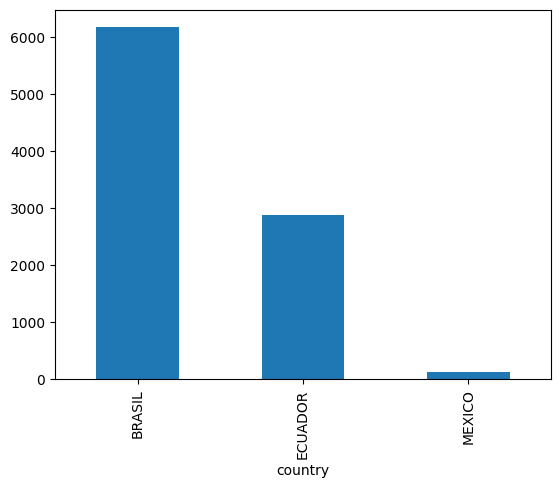

In [158]:
import matplotlib.pyplot as plt
grouped["followers"].plot(kind='bar')
plt.show()

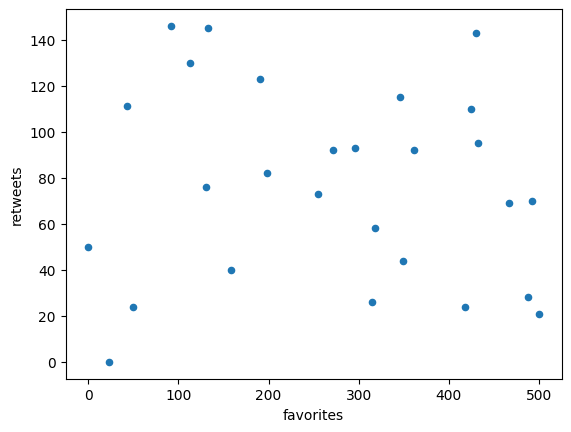

In [161]:
df.plot(kind= "scatter", x= "favorites", y= "retweets")
plt.show()